In [1]:
import numpy as np

X_train = np.array([[1, 6],
                    [2, 8],
                    [3, 5],
                    [4, 7],
                    [5, 6]])
y_train = np.array([43, 54, 50, 61, 63])

In [11]:
print(X_train.shape)

(5, 2)


In [12]:
print(X_train[2])

[3 5]


In [8]:
print(X_train[: ,1])

[6 8 5 7 6]


In [9]:
np.mean(X_train[: ,0])

np.float64(3.0)

In [15]:
def predict_multi(X, w,b):
    f=np.dot(X,w)+b
    return f

In [16]:
w_test = np.array([5, 3])
b_test = 20
print(predict_multi(X_train, w_test, b_test))

[43 54 50 61 63]


In [17]:
X_new = np.array([[6, 8]])
print(predict_multi(X_new, w_test, b_test))

[74]


In [20]:
def compute_cost_multi(X, y, w, b):
    m=X.shape[0]
    f=predict_multi(X,w,b)
    errors=f-y
    cost=(1/(2*m))*np.sum(errors**2)
    return cost


In [ ]:
w_test = np.array([5, 3])
print(compute_cost_multi(X_train, y_train, w_test, 20))   
print(compute_cost_multi(X_train, y_train, w_test, 19))   

0.0
0.5


In [22]:
print(compute_cost_multi(X_train, y_train, w_test, 18))
print(compute_cost_multi(X_train, y_train, w_test, 22))

2.0
2.0


In [31]:
def gradient_descent_multi(X, y, w_init, b_init, alpha, num_iters):
    w = w_init
    b = b_init
    cost_history = []

    for i in range(num_iters):
        dj_dw, dj_db =compute_gradient_multi(X,y,w,b)  
        w = w-alpha*dj_dw        
        b =b-alpha*dj_db
        cost = compute_cost_multi(X,y,w,b)
        cost_history.append(cost)

    return w, b, cost_history

In [25]:
def compute_gradient_multi(X, y, w, b):
    m = X.shape[0]
    errors = predict_multi(X, w, b) - y

    dj_dw1 = np.sum(errors * X[:, 0]) / m
    dj_dw2 = np.sum(errors * X[:, 1]) / m
    dj_dw = np.array([dj_dw1, dj_dw2])

    dj_db = np.sum(errors) / m

    return dj_dw, dj_db

In [ ]:
dj_dw, dj_db = compute_gradient_multi(X_train, y_train, np.array([5, 3]), 20)
print(dj_dw, dj_db)   

[0. 0.] 0.0


In [ ]:
dj_dw, dj_db = compute_gradient_multi(X_train, y_train, np.array([0, 0]), 0)
print(dj_dw, dj_db)   

[-172. -349.] -54.2


w: [5.67728398 5.07109652]
b: 4.404153472531986
final cost: 2.4564120539169405


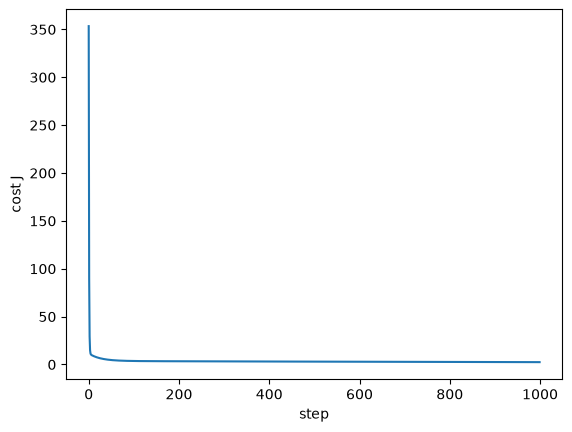

In [32]:
import matplotlib.pyplot as plt

w_init = np.zeros(2)
w_final, b_final, cost_history = gradient_descent_multi(
    X_train, y_train, w_init, 0, 0.01, 1000)

print("w:", w_final)
print("b:", b_final)
print("final cost:", cost_history[-1])

plt.plot(cost_history)
plt.xlabel("step")
plt.ylabel("cost J")
plt.show()

In [33]:
def zscore_normalize(X):
    mu = np.mean(X, axis=0)         
    sigma = np.std(X, axis=0)      
    X_norm = (X - mu) / sigma     
    return X_norm, mu, sigma

In [35]:
X_norm, mu, sigma = zscore_normalize(X_train)
print("mu:", mu)                                    
print("sigma:", sigma)                              
print(np.round(X_norm, 3))                          
print("new means:", np.mean(X_norm, axis=0))        
print("new stds:", np.std(X_norm, axis=0))        

mu: [3.  6.4]
sigma: [1.41421356 1.0198039 ]
[[-1.414 -0.392]
 [-0.707  1.569]
 [ 0.    -1.373]
 [ 0.707  0.588]
 [ 1.414 -0.392]]
new means: [ 0.00000000e+00 -3.88578059e-16]
new stds: [1. 1.]


w: [7.07106774 3.05941163]
b: 54.19999996176148
final cost: 5.716049738459902e-15


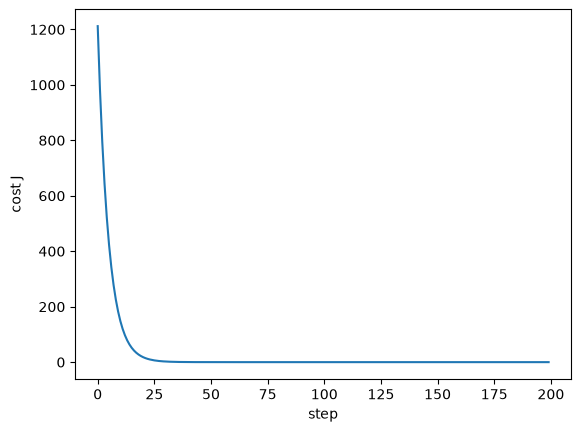

In [36]:
w_init = np.zeros(2)
w_final, b_final, cost_history = gradient_descent_multi(
    X_norm, y_train, w_init, 0, 0.1, 200)

print("w:", w_final)
print("b:", b_final)
print("final cost:", cost_history[-1])

plt.plot(cost_history)
plt.xlabel("step")
plt.ylabel("cost J")
plt.show()